In [ ]:

from google.colab import drive
from pathlib import Path

# Connect Google Drive to this Colab runtime.
drive.mount("/content/drive")

# Define the project's location inside My Drive.
PROJECT_DIR = Path("/content/drive/MyDrive/FireWatch-AI")

# Confirm that the project folder exists.
print("Project path:", PROJECT_DIR)
print("Folder exists:", PROJECT_DIR.exists())


Mounted at /content/drive
Project path: /content/drive/MyDrive/FireWatch-AI
Folder exists: True


In [ ]:
%pip install -q ultralytics

In [ ]:
# Verify that Ultralytics is installed and importable.
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("YOLO import successful.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.189
YOLO import successful.


In [ ]:

from pathlib import Path
from ultralytics import YOLO, __version__

# Store generated baseline results separately from original inputs.
PROJECT_DIR = Path("/content/drive/MyDrive/FireWatch-AI")
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project path:", PROJECT_DIR)
print("Project folder exists:", PROJECT_DIR.exists())
print("Output folder:", OUTPUT_DIR)
print("Ultralytics version:", __version__)

# Load pretrained weights; no custom training is performed.
model = YOLO("yolo26n.pt")

# Inspect the classes this checkpoint can predict.
print("\nNumber of supported classes:", len(model.names))
for class_id, class_name in model.names.items():
    print(f"{class_id}: {class_name}")

# Check our key project targets against the actual class list.
target_classes = {"person", "fire", "smoke", "helmet"}
available_classes = set(model.names.values())

print("\nTarget class availability:")
for class_name in sorted(target_classes):
    print(f"{class_name}: {class_name in available_classes}")


Project path: /content/drive/MyDrive/FireWatch-AI
Project folder exists: True
Output folder: /content/drive/MyDrive/FireWatch-AI/outputs
Ultralytics version: 8.4.189

Number of supported classes: 80
0: person
1: bicycle
2: car
3: motorcycle
4: airplane
5: bus
6: train
7: truck
8: boat
9: traffic light
10: fire hydrant
11: stop sign
12: parking meter
13: bench
14: bird
15: cat
16: dog
17: horse
18: sheep
19: cow
20: elephant
21: bear
22: zebra
23: giraffe
24: backpack
25: umbrella
26: handbag
27: tie
28: suitcase
29: frisbee
30: skis
31: snowboard
32: sports ball
33: kite
34: baseball bat
35: baseball glove
36: skateboard
37: surfboard
38: tennis racket
39: bottle
40: wine glass
41: cup
42: fork
43: knife
44: spoon
45: bowl
46: banana
47: apple
48: sandwich
49: orange
50: broccoli
51: carrot
52: hot dog
53: pizza
54: donut
55: cake
56: chair
57: couch
58: potted plant
59: bed
60: dining table
61: toilet
62: tv
63: laptop
64: mouse
65: remote
66: keyboard
67: cell phone
68: microwave
69:


--- bus ---
bus | confidence=0.881 | box=(0.0, 230.5, 803.2, 750.7)
person | confidence=0.872 | box=(48.6, 397.7, 240.3, 902.4)
person | confidence=0.861 | box=(222.9, 404.8, 345.5, 861.0)
person | confidence=0.846 | box=(669.6, 394.5, 809.9, 879.4)
person | confidence=0.656 | box=(0.2, 553.0, 59.7, 871.3)
Saved: /content/drive/MyDrive/FireWatch-AI/outputs/bus_baseline.jpg


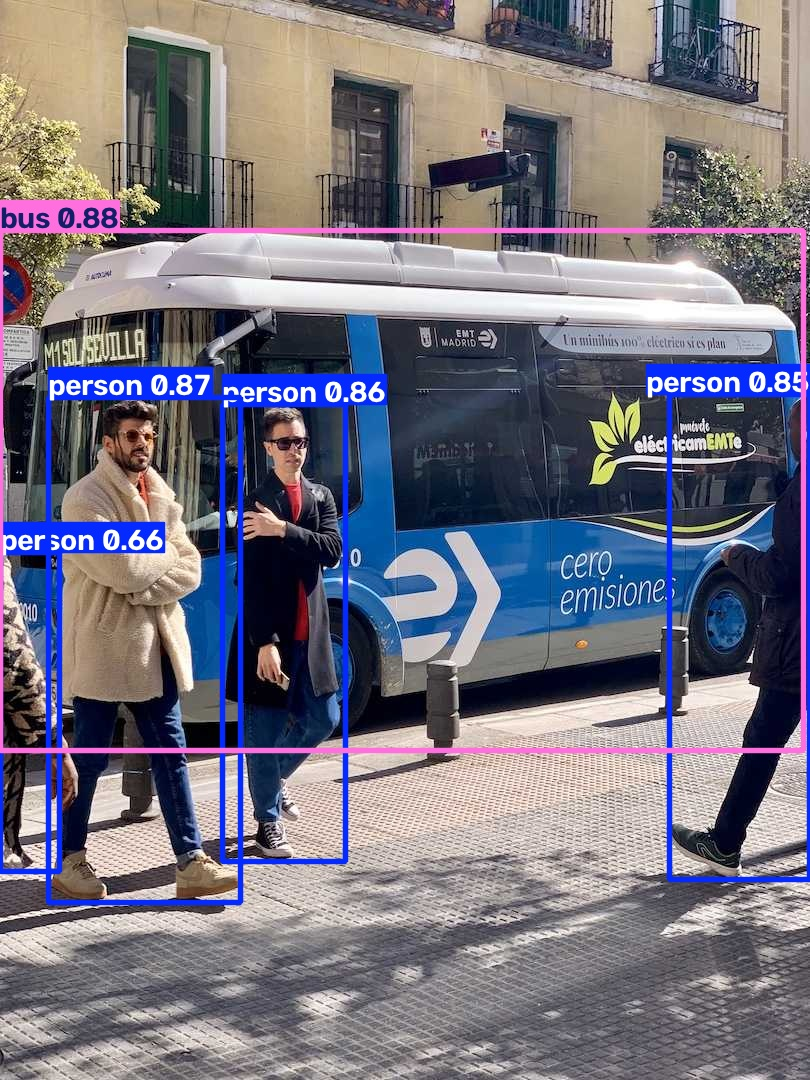


--- people ---
person | confidence=0.895 | box=(742.2, 40.1, 1150.8, 708.5)
person | confidence=0.853 | box=(119.2, 201.7, 1000.2, 712.8)
tie | confidence=0.584 | box=(436.0, 434.6, 526.2, 715.7)
Saved: /content/drive/MyDrive/FireWatch-AI/outputs/people_baseline.jpg


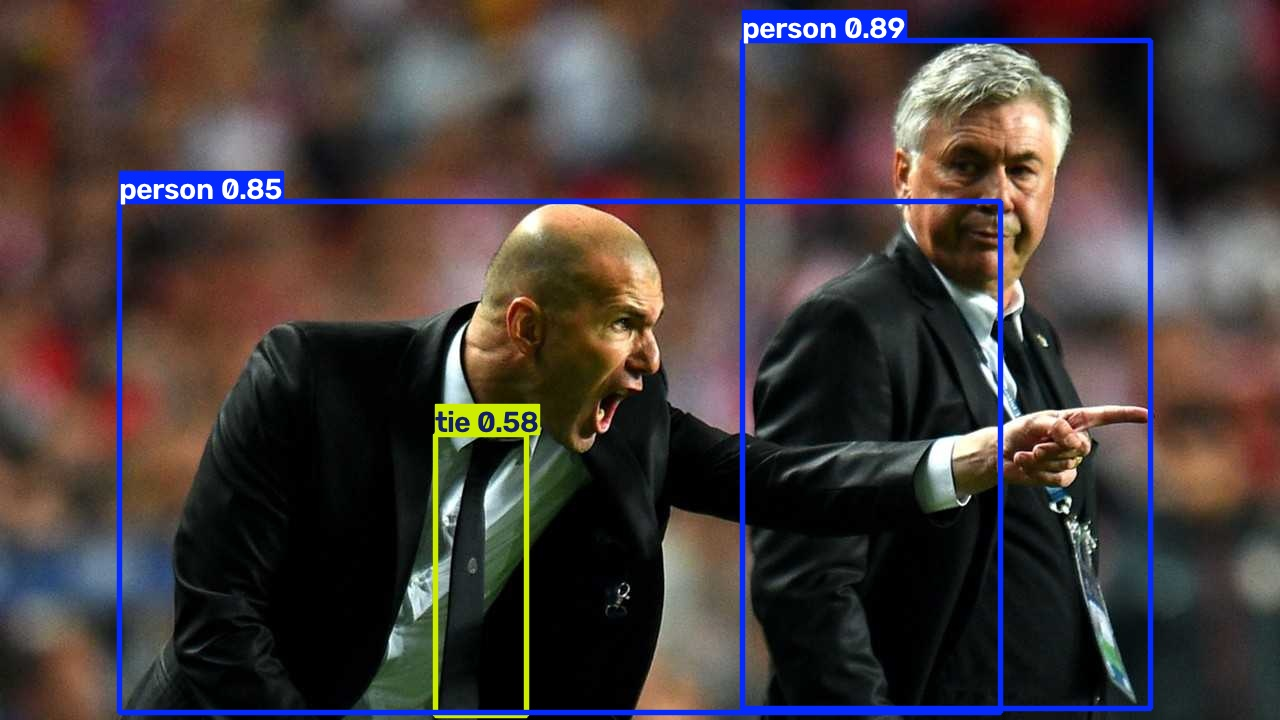

bus_baseline.jpg: exists=True
people_baseline.jpg: exists=True


In [ ]:

from pathlib import Path
from IPython.display import display, Image
from ultralytics import YOLO

# Keep generated images separate from original inputs.
PROJECT_DIR = Path("/content/drive/MyDrive/FireWatch-AI")
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reuse the pretrained model; no installation or training required.
model = YOLO("yolo26n.pt")

sample_images = {
    "bus": "https://ultralytics.com/images/bus.jpg",
    "people": "https://ultralytics.com/images/zidane.jpg",
}

for image_name, image_source in sample_images.items():
    # Run inference with a provisional confidence threshold of 0.25.
    result = model.predict(
        source=image_source,
        conf=0.25,
        verbose=False
    )[0]

    print(f"\n--- {image_name} ---")

    if result.boxes is None or len(result.boxes) == 0:
        print("No detections passed the confidence threshold.")
    else:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            x1, y1, x2, y2 = box.xyxy[0].tolist()

            print(
                f"{result.names[class_id]} | "
                f"confidence={confidence:.3f} | "
                f"box=({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})"
            )

    # Save an annotated copy without overwriting the source image.
    output_path = OUTPUT_DIR / f"{image_name}_baseline.jpg"
    result.save(filename=str(output_path))

    print("Saved:", output_path)
    display(Image(filename=str(output_path)))

# Verify that both expected output files exist.
for filename in ("bus_baseline.jpg", "people_baseline.jpg"):
    path = OUTPUT_DIR / filename
    print(f"{filename}: exists={path.is_file()}")


In [ ]:

import requests
from urllib.parse import urljoin

TIMEOUT = 20

SOURCES = {
    "dfire_api": "https://api.github.com/repos/gaia-solutions-on-demand/DFireDataset",
    "dfire_readme": "https://raw.githubusercontent.com/gaia-solutions-on-demand/DFireDataset/master/README.md",
    "ppe_yaml": "https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/cfg/datasets/construction-ppe.yaml",
    "ppe_archive": "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip",
    "mivia_page": "https://mivia.unisa.it/datasets/video-analysis-datasets/fire-detection-dataset/",
}

def get_response(url):
    """Fetch metadata/text only; do not download dataset archives."""
    try:
        response = requests.get(
            url,
            timeout=TIMEOUT,
            stream=True,  # Don't eagerly read a potentially large response.
            headers={"User-Agent": "FireWatch-AI-dataset-check/1.0"},
        )
        return response
    except requests.RequestException as exc:
        print(f"Request failed: {type(exc).__name__}: {exc}")
        return None

# 1. D-Fire: repository and license metadata.
response = get_response(SOURCES["dfire_api"])
if response is not None:
    print("\n[D-Fire GitHub API]", response.status_code)
    if response.ok:
        metadata = response.json()
        print("Repository:", metadata.get("html_url"))
        print("Default branch:", metadata.get("default_branch"))
        print("GitHub license field:", metadata.get("license"))
    response.close()

# Read only the README text to confirm published labels and host links.
response = get_response(SOURCES["dfire_readme"])
if response is not None:
    print("\n[D-Fire README]", response.status_code)
    if response.ok:
        readme = response.text
        for term in ("YOLO", "Training, validation and test", "Kaggle", "1drv.ms"):
            print(f"Contains {term!r}:", term.lower() in readme.lower())
    response.close()

# 2. Construction-PPE: inspect the live YAML class names.
response = get_response(SOURCES["ppe_yaml"])
if response is not None:
    print("\n[Construction-PPE YAML]", response.status_code)
    if response.ok:
        yaml_text = response.text
        print(yaml_text)
    response.close()

# Check archive headers only. Do not read or save the archive body.
try:
    response = requests.head(
        SOURCES["ppe_archive"],
        allow_redirects=True,
        timeout=TIMEOUT,
    )
    print("\n[Construction-PPE archive HEAD]", response.status_code)
    print("Resolved URL:", response.url)
    print("Content-Length:", response.headers.get("Content-Length"))
    response.close()
except requests.RequestException as exc:
    print("\n[PPE archive HEAD] Could not verify:", type(exc).__name__)

# 3. MIVIA: check page accessibility and list candidate download links.
response = get_response(SOURCES["mivia_page"])
if response is not None:
    print("\n[MIVIA page]", response.status_code)
    print("Resolved URL:", response.url)

    if response.ok:
        # Read HTML only; this does not follow dataset download links.
        from bs4 import BeautifulSoup

        html = response.text
        soup = BeautifulSoup(html, "html.parser")
        print("Page title:", soup.title.get_text(strip=True) if soup.title else None)

        for link in soup.find_all("a", href=True):
            href = urljoin(response.url, link["href"])
            label = link.get_text(" ", strip=True)
            if any(term in (href + " " + label).lower()
                   for term in ("download", ".zip", ".rar", ".7z")):
                print("Candidate link:", label or "(unnamed)", "->", href)

    response.close()



[D-Fire GitHub API] 200
Repository: https://github.com/gaia-solutions-on-demand/DFireDataset
Default branch: master
GitHub license field: {'key': 'other', 'name': 'Other', 'spdx_id': 'NOASSERTION', 'url': None, 'node_id': 'MDc6TGljZW5zZTA='}

[D-Fire README] 200
Contains 'YOLO': True
Contains 'Training, validation and test': True
Contains 'Kaggle': True
Contains '1drv.ms': True

[Construction-PPE YAML] 200
# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Construction-PPE dataset by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/detect/construction-ppe
# Example usage: yolo train data=construction-ppe.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── construction-ppe ← downloads here (178.4 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: construction-ppe # dataset root dir
train: images/train # train images (relative to 'path') 1132 images
val: images/val 

In [ ]:
!pip -q install roboflow pyyaml

from google.colab import drive, userdata
from pathlib import Path
from collections import Counter
import yaml

drive.mount("/content/drive")

API_KEY = userdata.get("ROBOFLOW_API_KEY")
assert API_KEY, "Add ROBOFLOW_API_KEY in Colab Secrets first."

from roboflow import Roboflow
rf = Roboflow(api_key=API_KEY)

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
ROOT.mkdir(parents=True, exist_ok=True)

DATASETS = [
    {
        "name": "fire_smoke_v2",
        "workspace": "fire-detection-h94rn",
        "project": "fire-and-smoke-detection-ydjqh",
        "version": 2,
    },
    {
        "name": "ppe_compliance_v2",
        "workspace": "izanagi",
        "project": "ppe-detection-and-compliance",
        "version": 2,
    },
]

def audit_dataset(name, dataset_dir):
    yaml_files = list(dataset_dir.rglob("data.yaml"))
    if not yaml_files:
        print(f"\n{name}: ERROR — data.yaml not found.")
        return

    config_path = yaml_files[0]
    config = yaml.safe_load(config_path.read_text())
    names = config.get("names", {})
    if isinstance(names, list):
        names = dict(enumerate(names))
    else:
        names = {int(k): v for k, v in names.items()}

    label_files = list(config_path.parent.rglob("*.txt"))
    # Exclude any unrelated text files outside the labels directory.
    label_files = [p for p in label_files if p.parent.name == "labels"]

    counts = Counter()
    malformed = 0
    empty = 0

    for label_file in label_files:
        lines = [line.strip() for line in label_file.read_text().splitlines()
                 if line.strip()]
        if not lines:
            empty += 1
        for line in lines:
            parts = line.split()
            try:
                if len(parts) != 5:
                    raise ValueError("Expected class + 4 box values")
                class_id = int(parts[0])
                box = [float(v) for v in parts[1:]]
                if class_id not in names or not all(0 <= v <= 1 for v in box):
                    raise ValueError("Invalid class ID or normalized box")
                counts[class_id] += 1
            except Exception:
                malformed += 1

    print(f"\n--- {name} ---")
    print("YAML:", config_path)
    print("Class names:", names)
    print("Dataset splits:", {
        key: config.get(key) for key in ("train", "val", "test")
        if config.get(key) is not None
    })
    print("Label files:", len(label_files))
    print("Empty label files:", empty)
    print("Malformed annotation rows:", malformed)
    print("Bounding-box counts by class:", {
        names.get(i, f"UNKNOWN_{i}"): n for i, n in sorted(counts.items())
    })

for item in DATASETS:
    dest = ROOT / item["name"]

    try:
        if not (dest / "data.yaml").exists():
            project = rf.workspace(item["workspace"]).project(item["project"])
            project.version(item["version"]).download(
                "yolov8", location=str(dest)
            )

        audit_dataset(item["name"], dest)

    except Exception as exc:
        print(f"\n{item['name']}: ACCESS/DOWNLOAD FAILED")
        print(type(exc).__name__, str(exc))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2 in yolov8:: 100%|██████████| 8620/8620 [01:37<00:00, 88.54it/s] 



--- fire_smoke_v2 ---
YAML: /content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2/data.yaml
Class names: {0: 'fire', 1: 'smoke'}
Dataset splits: {'train': '../train/images', 'val': '../valid/images', 'test': '../test/images'}
Label files: 4304
Empty label files: 0
Malformed annotation rows: 65
Bounding-box counts by class: {'fire': 3920, 'smoke': 2457}
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/FireWatch-AI/datasets/ppe_compliance_v2 in yolov8:: 100%|██████████| 19338/19338 [04:22<00:00, 73.80it/s]



--- ppe_compliance_v2 ---
YAML: /content/drive/MyDrive/FireWatch-AI/datasets/ppe_compliance_v2/data.yaml
Class names: {0: 'Boots', 1: 'Gloves', 2: 'Goggles', 3: 'Helmet', 4: 'Mask', 5: 'NO-Boots', 6: 'NO-Gloves', 7: 'NO-Goggles', 8: 'NO-Helmet', 9: 'NO-Mask', 10: 'NO-Vest', 11: 'Person', 12: 'Vest'}
Dataset splits: {'train': '../train/images', 'val': '../valid/images', 'test': '../test/images'}
Label files: 9663
Empty label files: 0
Malformed annotation rows: 109
Bounding-box counts by class: {'Boots': 1507, 'Gloves': 2543, 'Goggles': 2369, 'Helmet': 3125, 'Mask': 4207, 'NO-Boots': 776, 'NO-Gloves': 2707, 'NO-Goggles': 1828, 'NO-Helmet': 3663, 'NO-Mask': 4063, 'NO-Vest': 2714, 'Person': 4930, 'Vest': 4969}


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
assert ROOT.exists(), f"Dataset folder not found: {ROOT}"

OUT = ROOT / "validation_reports"
OUT.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", ROOT)
print("Validation reports:", OUT)

Mounted at /content/drive
Dataset directory: /content/drive/MyDrive/FireWatch-AI/datasets
Validation reports: /content/drive/MyDrive/FireWatch-AI/datasets/validation_reports


In [ ]:
from pathlib import Path
import pandas as pd

OUT = Path("/content/drive/MyDrive/FireWatch-AI/datasets/validation_reports")

print("Report files:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT)} ({p.stat().st_size:,} bytes)")

for name in ["summary.csv", "malformed_rows.csv"]:
    p = OUT / name
    if p.exists():
        print(f"\n--- {name} ---")
        df = pd.read_csv(p)
        print(df.head(25).to_string(index=False))
        print(f"Rows: {len(df)}")
    else:
        print(f"\n{name}: NOT FOUND")

Report files:

summary.csv: NOT FOUND

malformed_rows.csv: NOT FOUND


In [ ]:
# Fast, read-only audit: no downloads, training, or original-file changes.
from pathlib import Path
from collections import Counter, defaultdict
import yaml, csv, math

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
OUT = ROOT / "validation_reports"
OUT.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "fire_smoke_v2": ["fire", "smoke"],
    "ppe_compliance_v2": [
        "Helmet", "Mask", "Vest", "Goggles", "Person", "Boots", "Gloves",
        "NO-Boots", "NO-Gloves", "NO-Goggles", "NO-Helmet", "NO-Mask", "NO-Vest"
    ]
}
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
summary, issues, distributions = [], [], []

for ds, expected in EXPECTED.items():
    base = ROOT / ds
    yamls = list(base.rglob("data.yaml")) if base.exists() else []
    if len(yamls) != 1:
        summary.append([ds, "FAIL", "data.yaml missing/ambiguous"])
        continue

    yp = yamls[0]
    cfg = yaml.safe_load(yp.read_text())
    names = cfg.get("names", [])
    names = [names[k] for k in sorted(names, key=lambda x: int(x))] \
        if isinstance(names, dict) else list(names)

    splits, class_counts = {}, Counter()
    stems_by_split, total_bad, empty_labels = defaultdict(set), 0, 0

    for split, aliases in {
        "train": ["train"], "val": ["valid", "val"], "test": ["test"]
    }.items():
        pair = next(((base/a/"images", base/a/"labels", a)
                     for a in aliases
                     if (base/a/"images").is_dir() and (base/a/"labels").is_dir()), None)

        if not pair:
            splits[split] = "MISSING"
            continue

        imdir, lbdir, alias = pair
        images = {p.stem: p for p in imdir.rglob("*")
                  if p.is_file() and p.suffix.lower() in EXT}
        labels = {p.stem: p for p in lbdir.rglob("*.txt")}
        missing = set(images) - set(labels)
        orphan = set(labels) - set(images)
        stems_by_split[split] = set(images)

        for stem in missing:
            issues.append([ds, split, str(images[stem]), "", "IMAGE_WITHOUT_LABEL"])
        for stem in orphan:
            issues.append([ds, split, "", str(labels[stem]), "LABEL_WITHOUT_IMAGE"])

        bad = 0
        for stem, lp in labels.items():
            rows = [line.split() for line in lp.read_text(
                errors="replace").splitlines() if line.strip()]
            if not rows:
                empty_labels += 1
                issues.append([ds, split, str(images.get(stem, "")),
                               str(lp), "EMPTY_LABEL_FILE"])
            for row in rows:
                reason = None
                try:
                    if len(row) != 5:
                        raise ValueError("wrong_field_count")
                    fcid = float(row[0])
                    if not math.isfinite(fcid) or not fcid.is_integer():
                        raise ValueError("invalid_class_id")
                    cid = int(fcid)
                    x, y, w, h = map(float, row[1:])
                    if not 0 <= cid < len(names):
                        raise ValueError("class_id_out_of_range")
                    if not all(map(math.isfinite, [x, y, w, h])):
                        raise ValueError("non_finite_box")
                    if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                        raise ValueError("box_values_out_of_range")
                    if x-w/2 < -1e-6 or y-h/2 < -1e-6 or x+w/2 > 1+1e-6 or y+h/2 > 1+1e-6:
                        raise ValueError("box_outside_image")
                    class_counts[(split, names[cid])] += 1
                except Exception as e:
                    reason = str(e)
                    bad += 1
                    issues.append([ds, split, str(images.get(stem, "")),
                                   str(lp), reason + ": " + " ".join(row)])
        total_bad += bad
        splits[split] = f"{len(images)} images, {len(labels)} labels, {bad} bad rows"

    # Filename overlap is a fast warning, not proof of duplicate image content.
    overlap = (
        (stems_by_split["train"] & stems_by_split["val"]) |
        (stems_by_split["train"] & stems_by_split["test"]) |
        (stems_by_split["val"] & stems_by_split["test"])
    )
    for stem in sorted(overlap):
        issues.append([ds, "CROSS_SPLIT", stem, "", "DUPLICATE_FILENAME_STEM"])

    for (split, cls), count in sorted(class_counts.items()):
        distributions.append([ds, split, cls, count])

    summary.append([
        ds,
        "PASS" if names == expected else "FAIL",
        str(splits),
        total_bad,
        empty_labels,
        len(overlap),
        sum("WITHOUT_LABEL" in i[4] for i in issues if i[0] == ds),
    ])

def save(name, header, rows):
    with (OUT/name).open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(header)
        w.writerows(rows)

save("fast_summary.csv",
     ["dataset", "classes_match", "split_counts", "invalid_rows",
      "empty_label_files", "overlapping_filename_stems", "unpaired_files"],
     summary)
save("fast_issues.csv",
     ["dataset", "split", "image_or_stem", "label_file", "issue"],
     issues)
save("fast_class_counts.csv",
     ["dataset", "split", "class", "valid_box_count"], distributions)

print("SUMMARY")
for row in summary:
    print(row)
print("\nReports:", OUT)
print("Original annotations unchanged.")

SUMMARY
['fire_smoke_v2', 'PASS', "{'train': '3320 images, 3320 labels, 54 bad rows', 'val': '684 images, 684 labels, 8 bad rows', 'test': '300 images, 300 labels, 3 bad rows'}", 65, 0, 0, 0]
['ppe_compliance_v2', 'FAIL', "{'train': '7721 images, 7721 labels, 78 bad rows', 'val': '1460 images, 1460 labels, 24 bad rows', 'test': '482 images, 482 labels, 7 bad rows'}", 109, 0, 0, 0]

Reports: /content/drive/MyDrive/FireWatch-AI/datasets/validation_reports
Original annotations unchanged.


In [ ]:
from pathlib import Path

R = Path("/content/drive/MyDrive/FireWatch-AI/datasets/validation_reports")

print("Report directory exists:", R.exists())
print("Files found:")
for p in sorted(R.glob("*")):
    print(f"{p.name}  ({p.stat().st_size:,} bytes)")

Report directory exists: True
Files found:
fast_class_counts.csv  (1,620 bytes)
fast_issues.csv  (125,919 bytes)
fast_summary.csv  (463 bytes)


In [ ]:
from pathlib import Path
import pandas as pd

R = Path("/content/drive/MyDrive/FireWatch-AI/datasets/validation_reports")
issues = pd.read_csv(R / "fast_issues.csv")

print("Issue counts:")
display(
    issues.groupby(["dataset", "issue"])
    .size().reset_index(name="count")
    .sort_values(["dataset", "count"], ascending=[True, False])
)

print("\nSample issues:")
display(issues.groupby("dataset", group_keys=False).head(8))

Issue counts:


,dataset,issue,count
26,fire_smoke_v2,wrong_field_count: 1 1 0.11264355781249999 0.7...,6
2,fire_smoke_v2,wrong_field_count: 1 0.06466253125 1 0.0655184...,5
6,fire_smoke_v2,wrong_field_count: 1 0.28184441875 0.922861392...,4
8,fire_smoke_v2,wrong_field_count: 1 0.3717452265625 0.3519841...,4
9,fire_smoke_v2,wrong_field_count: 1 0.3835387796875 0.0206753...,4
...,...,...,...
131,ppe_compliance_v2,wrong_field_count: 7 0.703768921875 0.36222538...,1
132,ppe_compliance_v2,wrong_field_count: 7 0.71675795625 0.289359120...,1
133,ppe_compliance_v2,wrong_field_count: 8 0.3167365171875 0.3616418...,1
134,ppe_compliance_v2,wrong_field_count: 8 0.3365650078125 0.3533706...,1



Sample issues:


,dataset,split,image_or_stem,label_file,issue
0,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3717452265625 0.3519841...
1,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3717452265625 0.3519841...
2,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3835387796875 0.0206753...
3,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3835387796875 0.0206753...
4,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3835387796875 0.0206753...
5,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.411337865625 0.00635946...
6,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3717452265625 0.3519841...
7,fire_smoke_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/f...,/content/drive/MyDrive/FireWatch-AI/datasets/f...,wrong_field_count: 1 0.3717452265625 0.3519841...
65,ppe_compliance_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/p...,/content/drive/MyDrive/FireWatch-AI/datasets/p...,wrong_field_count: 1 0.56867186875 1 0.5723912...
66,ppe_compliance_v2,train,/content/drive/MyDrive/FireWatch-AI/datasets/p...,/content/drive/MyDrive/FireWatch-AI/datasets/p...,wrong_field_count: 1 1 0.55964315 0.8707706500...


In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
R = ROOT / "validation_reports"
issues = pd.read_csv(R / "fast_issues.csv")

counts = Counter()
examples = {}

for _, row in issues.iterrows():
    p = Path(row["label_file"])
    if not p.exists():
        continue
    for line_no, line in enumerate(p.read_text(errors="replace").splitlines(), 1):
        parts = line.split()
        if len(parts) != 5:
            key = (row["dataset"], len(parts))
            counts[key] += 1
            examples.setdefault(key, (str(p), line_no, line))

print("Malformed rows by dataset and field count:")
for key, count in sorted(counts.items()):
    print(key, "count =", count, "\nexample =", examples[key])

Malformed rows by dataset and field count:
('fire_smoke_v2', 17) count = 14 
example = ('/content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2/train/labels/b00253_jpg.rf.0c3aab0c0c7537288e8046d1814a501f.txt', 1, '1 0.3717452265625 0.3519841796875 0.36332126875 0.2599539265625 0.3978595453125 0.149517675 0.411337865625 0.0063594656250000004 0.3835387796875 0.020675378124999998 0.3372070125 0.2292771796875 0.35321254375 0.347894009375 0.3717452265625 0.3519841796875')
('fire_smoke_v2', 19) count = 11 
example = ('/content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2/train/labels/000117_jpg.rf.06c5883a45ab3c717907f13121374e50.txt', 5, '1 0.06466253125 1 0.065518428125 0.9324400171875 0.0852043875 0.6396520140625 0.1160171390625 0.446172046875 0.169939503125 0.28693643125 0.004748821875 0.3263172734375 0.0013251687499999999 0.319468403125 0 0.995791771875 0.06466253125 1')
('fire_smoke_v2', 21) count = 11 
example = ('/content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2/tra

In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import math

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
OUT = ROOT / "validation_reports"
issues = pd.read_csv(OUT / "fast_issues.csv")

seen = set()
results = []

for _, row in issues.iterrows():
    p = Path(row["label_file"])
    if not p.exists():
        continue

    for line_no, line in enumerate(p.read_text(errors="replace").splitlines(), 1):
        parts = line.split()
        if len(parts) == 5:
            continue

        key = (str(p), line_no)
        if key in seen:
            continue
        seen.add(key)

        try:
            cid = int(parts[0])
            coords = list(map(float, parts[1:]))
            if len(coords) < 6 or len(coords) % 2:
                status = "NOT_POLYGON_PAIR_FORMAT"
            elif not all(math.isfinite(v) and 0 <= v <= 1 for v in coords):
                status = "INVALID_COORDINATES"
            else:
                closed = (coords[0] == coords[-2] and coords[1] == coords[-1])
                status = "POLYGON_CLOSED" if closed else "POLYGON_OPEN"
        except Exception:
            status = "UNPARSABLE"

        results.append([row["dataset"], str(p), line_no, len(parts), status])

df = pd.DataFrame(results, columns=[
    "dataset", "label_file", "line", "field_count", "format_check"
])
display(df.groupby(["dataset", "format_check"]).size()
        .reset_index(name="rows"))
display(df.head(10))

df.to_csv(OUT / "polygon_format_check.csv", index=False)
print("Saved:", OUT / "polygon_format_check.csv")

,dataset,format_check,rows
0,fire_smoke_v2,POLYGON_CLOSED,65
1,ppe_compliance_v2,POLYGON_CLOSED,109


,dataset,label_file,line,field_count,format_check
0,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
1,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
2,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
3,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
4,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
5,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
6,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
7,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
8,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,17,POLYGON_CLOSED
9,fire_smoke_v2,/content/drive/MyDrive/FireWatch-AI/datasets/f...,1,35,POLYGON_CLOSED


Saved: /content/drive/MyDrive/FireWatch-AI/datasets/validation_reports/polygon_format_check.csv


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import yaml

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
REPORT_DIR = ROOT / "validation_reports"

# 1. Load the polygon audit and remove duplicate report entries
audit_path = REPORT_DIR / "polygon_format_check.csv"
audit = pd.read_csv(audit_path)

required = {"dataset", "label_file", "line", "field_count", "format_check"}
missing = required - set(audit.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

unique_rows = audit.drop_duplicates(subset=["dataset", "label_file", "line"])

print("=== UNIQUE AFFECTED ANNOTATION LINES ===")
print(
    unique_rows.groupby("dataset")
    .size()
    .rename("unique_lines")
    .to_string()
)
print(f"\nTotal unique rows: {len(unique_rows)}")

# 2. Validate each polygon row without changing its source file
results = []

for _, record in unique_rows.iterrows():
    label_path = Path(record["label_file"])
    line_no = int(record["line"])

    result = {
        "dataset": record["dataset"],
        "label_file": str(label_path),
        "line": line_no,
        "field_count": None,
        "class_id": None,
        "coordinate_pairs": None,
        "coordinates_in_0_1": False,
        "closed_polygon": False,
        "status": "UNREADABLE",
    }

    try:
        lines = label_path.read_text().splitlines()
        raw = lines[line_no - 1].strip()
        values = raw.split()
        result["field_count"] = len(values)

        if len(values) < 7 or (len(values) - 1) % 2 != 0:
            result["status"] = "INVALID_FIELD_COUNT"
        else:
            class_value = float(values[0])
            coords = np.asarray(values[1:], dtype=float).reshape(-1, 2)

            result["class_id"] = class_value
            result["coordinate_pairs"] = len(coords)

            finite = np.isfinite(coords).all()
            normalized = finite and ((coords >= 0) & (coords <= 1)).all()
            result["coordinates_in_0_1"] = bool(normalized)

            closed = (
                len(coords) >= 4
                and np.allclose(coords[0], coords[-1], atol=1e-6)
            )
            result["closed_polygon"] = bool(closed)

            if not finite:
                result["status"] = "NONFINITE_COORDINATES"
            elif not normalized:
                result["status"] = "OUT_OF_RANGE_COORDINATES"
            elif class_value < 0 or not class_value.is_integer():
                result["status"] = "INVALID_CLASS_ID"
            elif len(coords) < 4:
                result["status"] = "TOO_FEW_POINTS"
            elif not closed:
                result["status"] = "OPEN_POLYGON"
            else:
                result["status"] = "VALID_CLOSED_POLYGON"

    except Exception as exc:
        result["status"] = f"READ_ERROR: {type(exc).__name__}"

    results.append(result)

validation = pd.DataFrame(results)
print("\n=== POLYGON VALIDATION RESULTS ===")
print(validation["status"].value_counts(dropna=False).to_string())

# Save a separate report; original labels remain untouched
output_path = REPORT_DIR / "polygon_validation_details.csv"
validation.to_csv(output_path, index=False)
print(f"\nSaved validation report: {output_path}")

# 3. Locate and inspect dataset YAML configuration files
print("\n=== DATASET YAML FILES ===")
yaml_paths = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {".yaml", ".yml"}
    and "validation_reports" not in p.parts
)

if not yaml_paths:
    print("No YAML files found under the datasets directory.")
else:
    for path in yaml_paths:
        print(f"\n--- {path} ---")
        try:
            config = yaml.safe_load(path.read_text()) or {}
            for key in ("path", "train", "val", "test", "names", "nc", "task"):
                if key in config:
                    print(f"{key}: {config[key]}")
        except Exception as exc:
            print(f"Could not parse YAML: {exc}")


=== UNIQUE AFFECTED ANNOTATION LINES ===
dataset
fire_smoke_v2         65
ppe_compliance_v2    109

Total unique rows: 174

=== POLYGON VALIDATION RESULTS ===
status
VALID_CLOSED_POLYGON    174

Saved validation report: /content/drive/MyDrive/FireWatch-AI/datasets/validation_reports/polygon_validation_details.csv

=== DATASET YAML FILES ===

--- /content/drive/MyDrive/FireWatch-AI/datasets/fire_smoke_v2/data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images
names: ['fire', 'smoke']
nc: 2

--- /content/drive/MyDrive/FireWatch-AI/datasets/ppe_compliance_v2/data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images
names: ['Boots', 'Gloves', 'Goggles', 'Helmet', 'Mask', 'NO-Boots', 'NO-Gloves', 'NO-Goggles', 'NO-Helmet', 'NO-Mask', 'NO-Vest', 'Person', 'Vest']
nc: 13


In [ ]:

from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
import yaml

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
REPORT_DIR = ROOT / "validation_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "fire_smoke_v2": 2,
    "ppe_compliance_v2": 13,
}

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
summary = []
class_counts = []
issues = []

for dataset_name, expected_nc in DATASETS.items():
    ds_root = ROOT / dataset_name
    yaml_path = ds_root / "data.yaml"
    config = yaml.safe_load(yaml_path.read_text())

    names = config.get("names", [])
    nc = int(config.get("nc", len(names)))

    print(f"\n{'=' * 60}\n{dataset_name}")
    print("YAML class count:", nc)
    print("Class names:", names)

    split_stats = defaultdict(Counter)
    split_classes = defaultdict(Counter)
    label_files_seen = set()

    # Find image/label files under this dataset's own directory.
    for split in ("train", "valid", "val", "test"):
        split_dir = ds_root / split
        image_dir = split_dir / "images"
        label_dir = split_dir / "labels"

        images = [
            p for p in image_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in image_exts
        ] if image_dir.exists() else []

        labels = sorted(label_dir.rglob("*.txt")) if label_dir.exists() else []

        # Avoid counting val and valid as two separate splits.
        display_split = "val" if split in ("valid", "val") else split
        if split == "val" and (ds_root / "valid").exists():
            continue

        split_stats[display_split]["images"] += len(images)
        split_stats[display_split]["label_files"] += len(labels)

        for label_path in labels:
            if label_path in label_files_seen:
                continue
            label_files_seen.add(label_path)

            try:
                lines = label_path.read_text().splitlines()
            except Exception as exc:
                issues.append({
                    "dataset": dataset_name,
                    "file": str(label_path),
                    "line": None,
                    "issue": f"READ_ERROR: {exc}",
                })
                continue

            for line_no, raw in enumerate(lines, start=1):
                raw = raw.strip()
                if not raw:
                    continue

                fields = raw.split()
                fmt = (
                    "BBOX"
                    if len(fields) == 5
                    else "POLYGON"
                    if len(fields) >= 7 and (len(fields) - 1) % 2 == 0
                    else "OTHER"
                )
                split_stats[display_split][f"{fmt}_rows"] += 1

                try:
                    class_float = float(fields[0])
                    coords = np.asarray(fields[1:], dtype=float)

                    if not class_float.is_integer():
                        raise ValueError("non-integer class ID")

                    class_id = int(class_float)
                    split_classes[display_split][class_id] += 1

                    if class_id < 0 or class_id >= nc:
                        issues.append({
                            "dataset": dataset_name,
                            "file": str(label_path),
                            "line": line_no,
                            "issue": f"CLASS_ID_OUT_OF_RANGE: {class_id}",
                        })

                    if not np.isfinite(coords).all():
                        issues.append({
                            "dataset": dataset_name,
                            "file": str(label_path),
                            "line": line_no,
                            "issue": "NONFINITE_COORDINATES",
                        })
                    elif np.any(coords < 0) or np.any(coords > 1):
                        issues.append({
                            "dataset": dataset_name,
                            "file": str(label_path),
                            "line": line_no,
                            "issue": "COORDINATES_OUT_OF_RANGE",
                        })

                    if fmt == "BBOX" and len(coords) == 4:
                        x, y, w, h = coords
                        if w <= 0 or h <= 0:
                            issues.append({
                                "dataset": dataset_name,
                                "file": str(label_path),
                                "line": line_no,
                                "issue": "NONPOSITIVE_BBOX_SIZE",
                            })

                except Exception as exc:
                    issues.append({
                        "dataset": dataset_name,
                        "file": str(label_path),
                        "line": line_no,
                        "issue": f"PARSE_ERROR: {exc}",
                    })

    for split, stats in split_stats.items():
        summary.append({
            "dataset": dataset_name,
            "split": split,
            "images": stats["images"],
            "label_files": stats["label_files"],
            "bbox_rows": stats["BBOX_rows"],
            "polygon_rows": stats["POLYGON_rows"],
            "other_rows": stats["OTHER_rows"],
            "yaml_nc": nc,
            "yaml_names_count": len(names),
        })

    for split, counts in split_classes.items():
        for class_id, count in sorted(counts.items()):
            class_name = (
                names[class_id]
                if isinstance(names, list) and 0 <= class_id < len(names)
                else names.get(class_id, names.get(str(class_id), "UNKNOWN"))
                if isinstance(names, dict)
                else "UNKNOWN"
            )
            class_counts.append({
                "dataset": dataset_name,
                "split": split,
                "class_id": class_id,
                "class_name": class_name,
                "label_rows": count,
            })

summary_df = pd.DataFrame(summary)
classes_df = pd.DataFrame(class_counts)
issues_df = pd.DataFrame(issues)

summary_df.to_csv(REPORT_DIR / "full_label_audit_summary.csv", index=False)
classes_df.to_csv(REPORT_DIR / "full_label_audit_classes.csv", index=False)
issues_df.to_csv(REPORT_DIR / "full_label_audit_issues.csv", index=False)

print("\n=== SPLIT AND ANNOTATION FORMAT SUMMARY ===")
print(summary_df.to_string(index=False))

print("\n=== CLASS DISTRIBUTION ===")
print(classes_df.to_string(index=False))

print("\n=== ISSUE COUNTS ===")
if issues_df.empty:
    print("No class-ID, coordinate, or parsing issues detected.")
else:
    print(issues_df["issue"].value_counts().to_string())
    print("\nSample issues:")
    print(issues_df.head(15).to_string(index=False))

print("\nReports saved in:", REPORT_DIR)



fire_smoke_v2
YAML class count: 2
Class names: ['fire', 'smoke']

ppe_compliance_v2
YAML class count: 13
Class names: ['Boots', 'Gloves', 'Goggles', 'Helmet', 'Mask', 'NO-Boots', 'NO-Gloves', 'NO-Goggles', 'NO-Helmet', 'NO-Mask', 'NO-Vest', 'Person', 'Vest']

=== SPLIT AND ANNOTATION FORMAT SUMMARY ===
          dataset split  images  label_files  bbox_rows  polygon_rows  other_rows  yaml_nc  yaml_names_count
    fire_smoke_v2 train    3320         3320       4870            54           0        2                 2
    fire_smoke_v2   val     684          684       1030             8           0        2                 2
    fire_smoke_v2  test     300          300        477             3           0        2                 2
ppe_compliance_v2 train    7721         7721      31600            78           0       13                13
ppe_compliance_v2   val    1460         1460       5830            24           0       13                13
ppe_compliance_v2  test     482          

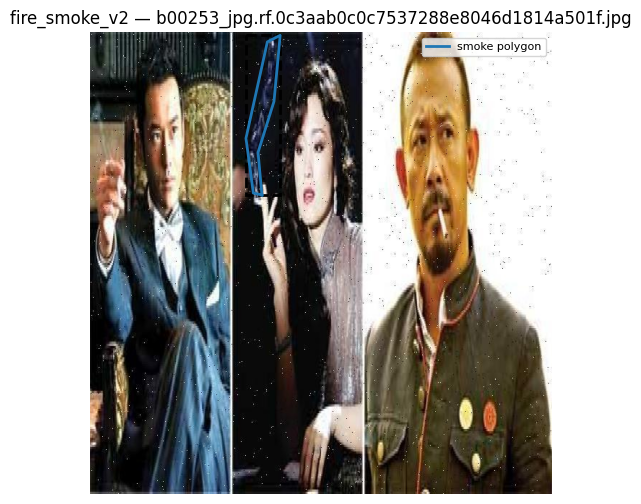

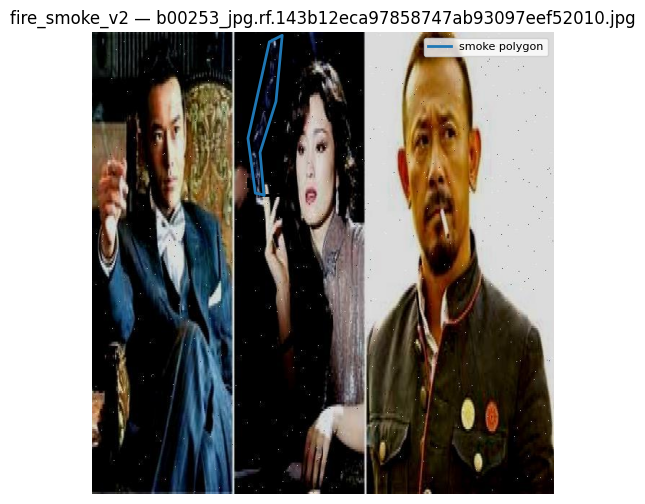

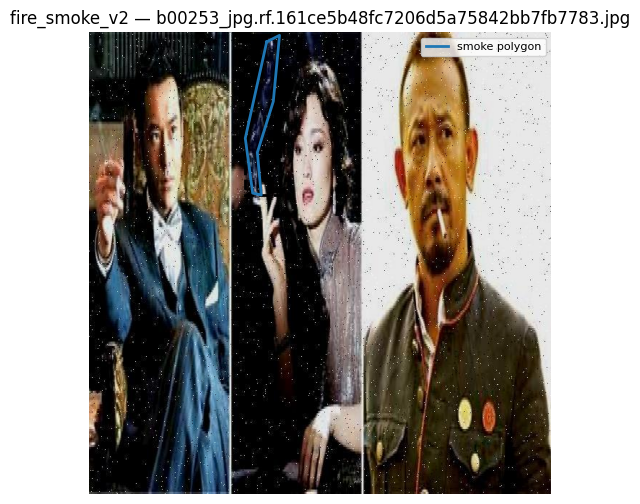

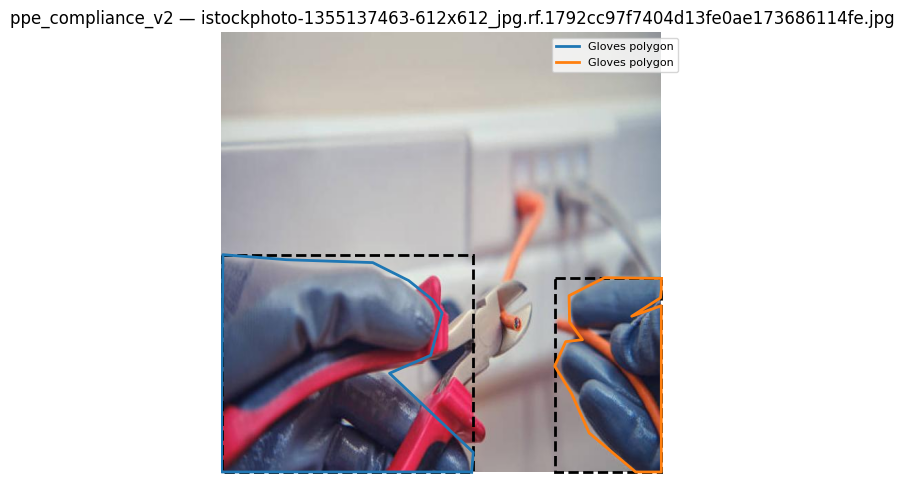

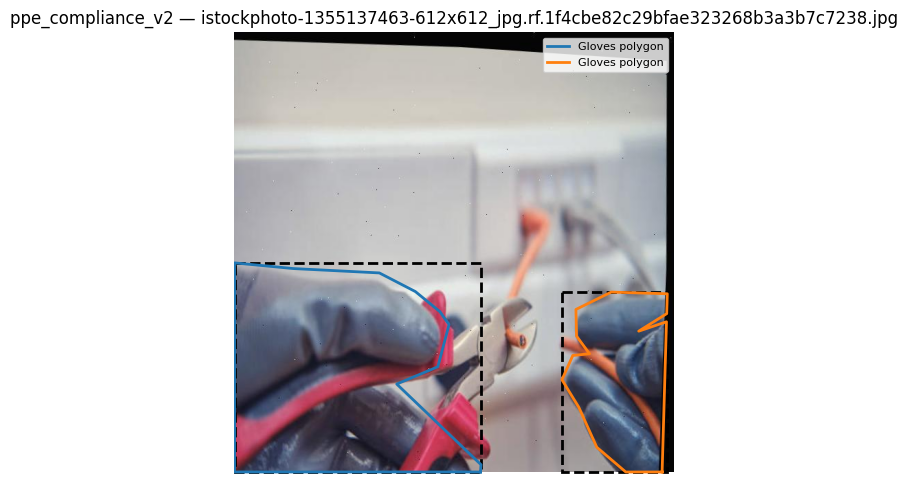

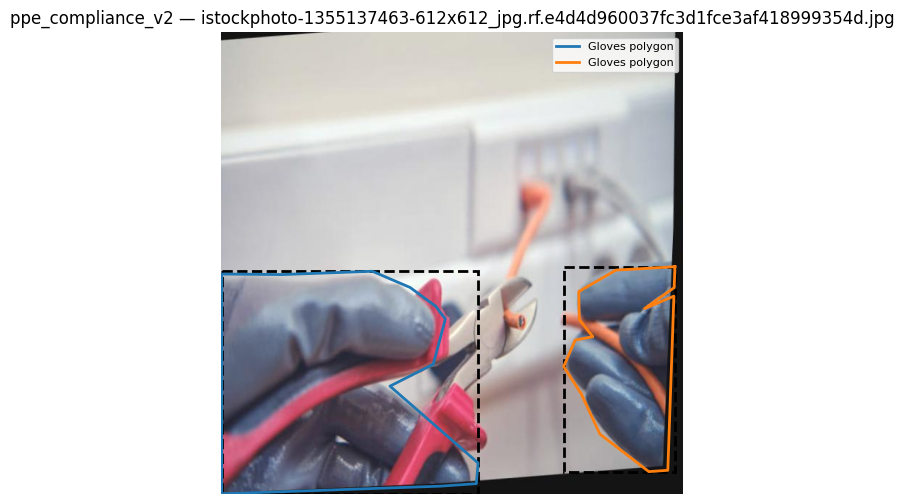

Displayed 6 polygon-labelled images.
Solid outlines = polygon; dashed rectangles = proposed bounding boxes.


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
REPORT_DIR = ROOT / "validation_reports"

audit = pd.read_csv(REPORT_DIR / "polygon_format_check.csv")
audit = audit.drop_duplicates(subset=["dataset", "label_file", "line"])

datasets = {
    "fire_smoke_v2": ["fire", "smoke"],
    "ppe_compliance_v2": [
        "Boots", "Gloves", "Goggles", "Helmet", "Mask",
        "NO-Boots", "NO-Gloves", "NO-Goggles", "NO-Helmet",
        "NO-Mask", "NO-Vest", "Person", "Vest"
    ],
}

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
shown = 0

for dataset_name, class_names in datasets.items():
    subset = audit[
        (audit["dataset"] == dataset_name)
        & (audit["format_check"] == "POLYGON_CLOSED")
    ]

    # Show up to 3 distinct polygon-labelled images per dataset.
    shown_files = set()

    for _, row in subset.iterrows():
        label_path = Path(row["label_file"])
        if label_path in shown_files:
            continue

        image_dir = label_path.parent.parent / "images"
        candidates = [
            p for p in image_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in image_extensions
            and p.stem == label_path.stem
        ]

        if not candidates:
            print("Image not found for:", label_path)
            continue

        image_path = candidates[0]
        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        lines = label_path.read_text().splitlines()
        polygons = []

        for raw in lines:
            fields = raw.split()
            if len(fields) >= 7 and (len(fields) - 1) % 2 == 0:
                values = np.asarray(fields[1:], dtype=float)
                points = values.reshape(-1, 2)

                # Remove the duplicated closing point for display.
                if len(points) > 1 and np.allclose(points[0], points[-1]):
                    points = points[:-1]

                pixels = points * np.array([width, height])
                x_min, y_min = pixels.min(axis=0)
                x_max, y_max = pixels.max(axis=0)

                polygons.append((
                    int(float(fields[0])),
                    pixels,
                    (x_min, y_min, x_max, y_max)
                ))

        if not polygons:
            continue

        fig, ax = plt.subplots(figsize=(9, 6))
        ax.imshow(image)

        for class_id, points, box in polygons:
            x_min, y_min, x_max, y_max = box
            class_name = (
                class_names[class_id]
                if 0 <= class_id < len(class_names)
                else f"UNKNOWN_{class_id}"
            )

            closed_points = np.vstack([points, points[0]])
            ax.plot(
                closed_points[:, 0],
                closed_points[:, 1],
                linewidth=2,
                label=f"{class_name} polygon"
            )

            rect = plt.Rectangle(
                (x_min, y_min),
                x_max - x_min,
                y_max - y_min,
                fill=False,
                linewidth=2,
                linestyle="--"
            )
            ax.add_patch(rect)

        ax.set_title(f"{dataset_name} — {image_path.name}")
        ax.axis("off")
        ax.legend(loc="upper right", fontsize=8)
        plt.show()

        shown_files.add(label_path)
        shown += 1

        if len(shown_files) >= 3:
            break

print(f"Displayed {shown} polygon-labelled images.")
print("Solid outlines = polygon; dashed rectangles = proposed bounding boxes.")




Preview: fire_smoke_v2


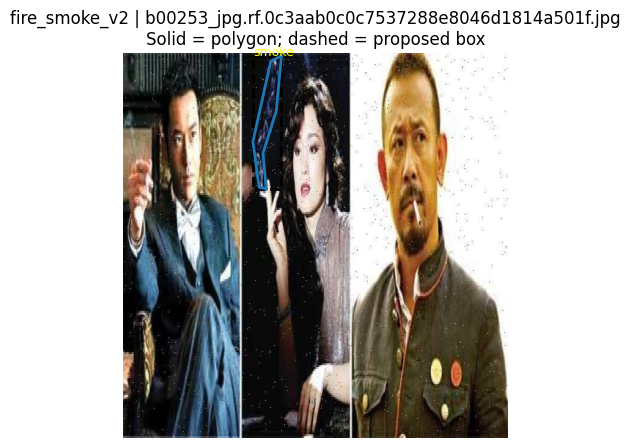

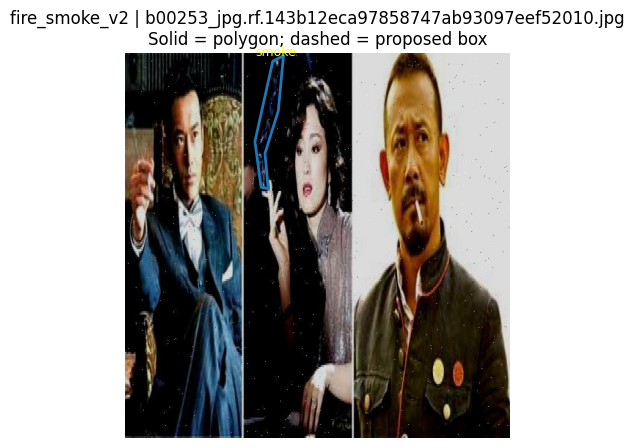

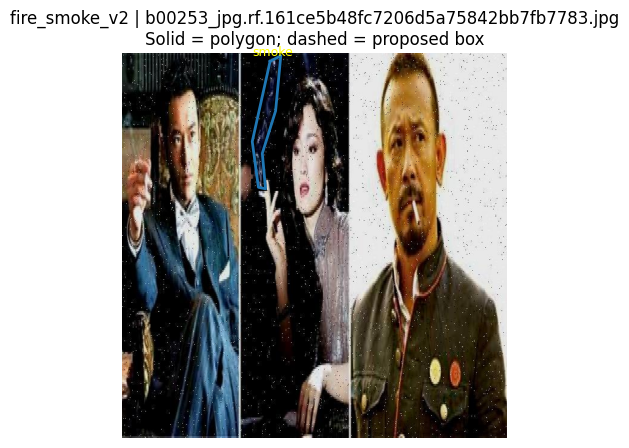


Preview: ppe_compliance_v2


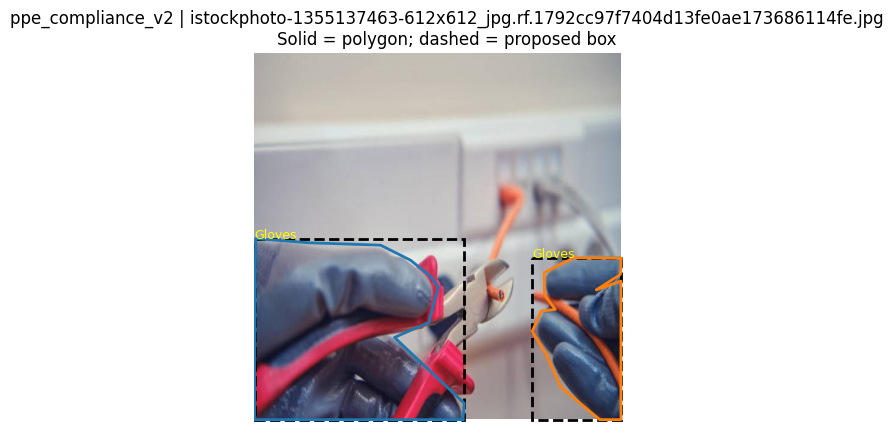

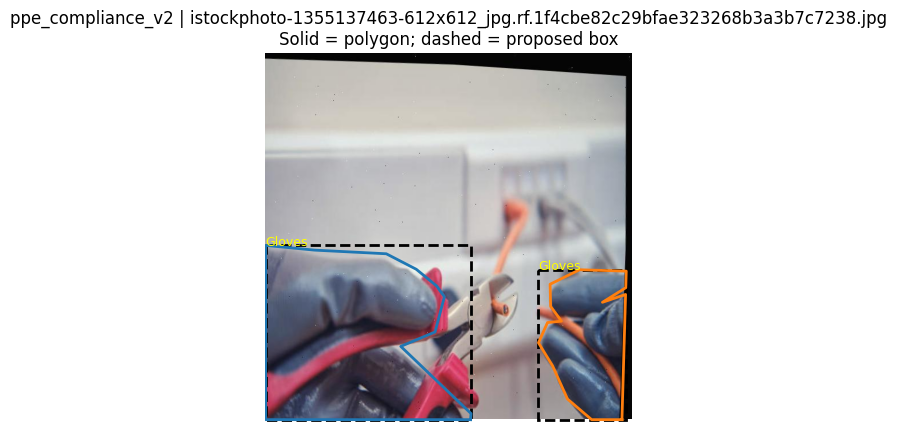

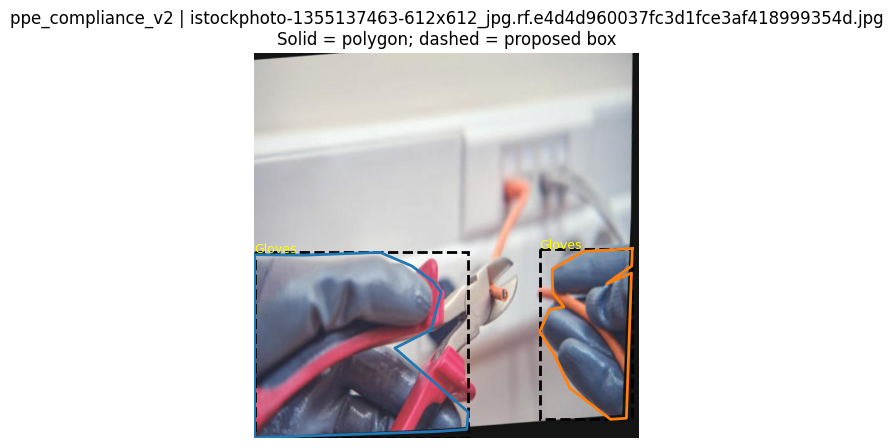

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/content/drive/MyDrive/FireWatch-AI/datasets")
audit = pd.read_csv(ROOT / "validation_reports/polygon_format_check.csv")
audit = audit.drop_duplicates(subset=["dataset", "label_file", "line"])

class_names = {
    "fire_smoke_v2": ["fire", "smoke"],
    "ppe_compliance_v2": [
        "Boots", "Gloves", "Goggles", "Helmet", "Mask",
        "NO-Boots", "NO-Gloves", "NO-Goggles", "NO-Helmet",
        "NO-Mask", "NO-Vest", "Person", "Vest"
    ]
}

for dataset, names in class_names.items():
    rows = audit[audit["dataset"] == dataset]
    shown = set()
    print(f"\nPreview: {dataset}")

    for _, row in rows.iterrows():
        label = Path(row["label_file"])
        if label in shown:
            continue

        ds_root = ROOT / dataset
        matches = [
            p for split in ["train", "valid", "test"]
            for p in (ds_root / split / "images").glob(label.stem + ".*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
        ]
        if not matches:
            continue

        img = Image.open(matches[0]).convert("RGB")
        w, h = img.size
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.imshow(img)

        for line in label.read_text().splitlines():
            f = line.split()
            if len(f) < 7 or (len(f) - 1) % 2:
                continue

            cid = int(float(f[0]))
            pts = np.array(f[1:], dtype=float).reshape(-1, 2)
            pts *= [w, h]
            xmin, ymin = pts.min(axis=0)
            xmax, ymax = pts.max(axis=0)

            closed = np.vstack([pts, pts[0]])
            ax.plot(closed[:, 0], closed[:, 1], linewidth=2)
            ax.add_patch(plt.Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                fill=False, linestyle="--", linewidth=2
            ))
            name = names[cid] if 0 <= cid < len(names) else str(cid)
            ax.text(xmin, ymin, name, color="yellow", fontsize=9)

        ax.set_title(f"{dataset} | {matches[0].name}\nSolid = polygon; dashed = proposed box")
        ax.axis("off")
        plt.show()

        shown.add(label)
        if len(shown) == 3:
            break


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/FireWatch-AI/datasets/candidates")

for name in ["fire_smoke_v2", "ppe_compliance_v2"]:
    p = root / f"{name}_bbox_candidate"
    yaml_file = p / "data.yaml"

    if not p.exists():
        status = "NOT CREATED"
    elif not yaml_file.exists():
        status = "INCOMPLETE COPY"
    else:
        status = "CANDIDATE EXISTS"

    print(f"{name}: {status}")


fire_smoke_v2: INCOMPLETE COPY
ppe_compliance_v2: INCOMPLETE COPY


In [9]:
from pathlib import Path

root = Path("/content/drive/MyDrive/FireWatch-AI/datasets")

for name in ["fire_smoke_v2", "ppe_compliance_v2"]:
    p = root / name
    print(
        name,
        "| exists:", p.exists(),
        "| YAML:", (p / "data.yaml").exists(),
        "| train:", (p / "train").exists()
    )

fire_smoke_v2 | exists: False | YAML: False | train: False
ppe_compliance_v2 | exists: False | YAML: False | train: False


In [3]:
from pathlib import Path
from google.colab import drive

# Try the existing mount first.
base = Path("/content/drive/MyDrive/FireWatch-AI/datasets")

if base.exists() and (base / "fire_smoke_v2").exists():
    print("Original datasets found at existing mount.")
else:
    # Use a fresh mountpoint; don't delete anything.
    mountpoint = "/content/gdrive_reconnect"
    Path(mountpoint).mkdir(exist_ok=True)
    drive.mount(mountpoint)

    base = Path(mountpoint) / "MyDrive/FireWatch-AI/datasets"

for name in ["fire_smoke_v2", "ppe_compliance_v2"]:
    p = base / name
    print(name, "| exists:", p.exists(), "| YAML:", (p / "data.yaml").exists())


Mounted at /content/gdrive_reconnect
fire_smoke_v2 | exists: True | YAML: True
ppe_compliance_v2 | exists: True | YAML: True


In [4]:
from pathlib import Path
import shutil, yaml
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive_reconnect/MyDrive/FireWatch-AI/datasets")
OUT = ROOT / "candidates"
OUT.mkdir(exist_ok=True)

results = []

for name in ["fire_smoke_v2", "ppe_compliance_v2"]:
    src = ROOT / name
    dst = OUT / f"{name}_bbox_candidate"

    assert (src / "data.yaml").is_file(), f"Missing source YAML: {src}"

    # Rebuild only the candidate copy; originals remain untouched.
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

    cfg = yaml.safe_load((dst / "data.yaml").read_text())
    nc = int(cfg.get("nc", len(cfg["names"])))
    converted = preserved = 0

    for label in dst.rglob("*.txt"):
        if label.parent.name != "labels":
            continue

        out_lines = []
        for line_no, raw in enumerate(label.read_text().splitlines(), 1):
            f = raw.split()
            if not f:
                continue

            cid = float(f[0])
            coords = np.asarray(f[1:], dtype=float)

            if not cid.is_integer() or not 0 <= int(cid) < nc:
                raise ValueError(f"Invalid class ID: {label}:{line_no}")
            if not np.isfinite(coords).all() or np.any(coords < 0) or np.any(coords > 1):
                raise ValueError(f"Invalid coordinates: {label}:{line_no}")

            if len(f) == 5:
                out_lines.append(raw)
                preserved += 1
            elif len(f) >= 7 and (len(f)-1) % 2 == 0:
                pts = coords.reshape(-1, 2)
                xmin, ymin = pts.min(axis=0)
                xmax, ymax = pts.max(axis=0)
                box = [(xmin+xmax)/2, (ymin+ymax)/2,
                       xmax-xmin, ymax-ymin]
                if box[2] <= 0 or box[3] <= 0:
                    raise ValueError(f"Invalid polygon: {label}:{line_no}")
                out_lines.append(
                    str(int(cid)) + " " + " ".join(f"{v:.8f}" for v in box)
                )
                converted += 1
            else:
                raise ValueError(f"Unexpected format: {label}:{line_no}")

        label.write_text("\n".join(out_lines) + ("\n" if out_lines else ""))

    cfg["path"] = str(dst)
    cfg["train"], cfg["val"], cfg["test"] = (
        "train/images", "valid/images", "test/images"
    )
    (dst / "data.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))

    results.append({
        "dataset": name,
        "polygons_converted": converted,
        "boxes_preserved": preserved,
        "candidate_yaml_exists": (dst / "data.yaml").exists()
    })
    print("Finished:", name)

report = pd.DataFrame(results)
report.to_csv(ROOT / "validation_reports/bbox_conversion_report.csv", index=False)
print("\n", report.to_string(index=False))
print("\nOriginal datasets untouched. Training has not started.")


KeyboardInterrupt: 

In [1]:

from pathlib import Path

PROJECT = Path("/content/gdrive_reconnect/MyDrive/FireWatch-AI")

folders = [
    "app",
    "configs",
    "src/firewatch/data",
    "src/firewatch/detection",
    "src/firewatch/temporal",
    "src/firewatch/risk",
    "src/firewatch/video",
    "src/firewatch/tracking",
    "scripts",
    "tests/unit",
    "tests/integration",
    "docs/architecture",
    "docs/datasets",
    "docs/experiments",
    "models/fire_smoke",
    "models/ppe",
    "runs",
    "logs",
    "mlruns",
    "dvc",
]

for folder in folders:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

files = {
    ".gitignore": """
# Python
__pycache__/
*.py[cod]
.venv/
venv/
.env

# Datasets and model artifacts
datasets/
models/**/*.pt
models/**/*.onnx
runs/
logs/
mlruns/
*.mp4
*.avi

# Notebooks
.ipynb_checkpoints/

# OS/editor
.DS_Store
.vscode/
""".lstrip(),

    "README.md": """
# FireWatch AI

A modular computer-vision system for fire/smoke detection,
PPE compliance monitoring, temporal event analysis, and
explainable safety-risk alerts from prerecorded videos.

## Core components

- Fire/smoke detection using YOLO
- PPE detection using YOLO
- Temporal event confirmation and fire-progression analysis
- Explainable risk-scoring engine
- Video annotation and processing
- Streamlit dashboard
- MLflow experiment tracking
- DVC data/model versioning

## Development environment

Google Colab and Google Drive.

## Project status

- [x] Initial pretrained YOLO baseline inspection
- [x] Dataset extraction and initial annotation audit
- [ ] Bounding-box candidate preparation
- [ ] Fire/smoke model training and evaluation
- [ ] PPE model training and evaluation
- [ ] Temporal video dataset selection
- [ ] Temporal analysis and risk engine
- [ ] Streamlit dashboard
- [ ] MLflow and DVC integration
- [ ] Automated tests and end-to-end validation

Training must only begin after the relevant dataset labels
are ready for the selected YOLO detection task.
""".lstrip(),

    "configs/README.md": """
Store model, dataset, training, temporal-analysis, and risk-engine
configuration here. Keep thresholds configurable rather than
hard-coded in application logic.
""".lstrip(),

    "docs/PROJECT_STATUS.md": """
# FireWatch AI — Project Status

## Locked
- YOLO-based detection
- Separate fire/smoke and PPE models
- Temporal analysis as an independent module
- Prerecorded image/video inputs initially
- Streamlit, MLflow, and DVC
- Modular, testable, readable code
- Preserve original datasets and document annotation conversions

## Implemented
- Colab/Drive setup
- Pretrained YOLO baseline inspection
- Dataset extraction and initial audit

## Pending
- Finish dataset candidate preparation
- Train and evaluate both detection models
- Select a genuine temporal video dataset
- Implement temporal analysis and risk scoring
- Build dashboard and integrate MLflow/DVC
- Run integration and end-to-end tests

## Code conventions
- Use descriptive names and focused functions.
- Add comments to explain intent or non-obvious logic.
- Avoid unnecessary comments and duplicated code.
- Keep secrets and large artifacts out of Git.
- Never modify original dataset annotations in place.
""".lstrip(),

    "src/firewatch/__init__.py": "",
    "src/firewatch/data/__init__.py": "",
    "src/firewatch/detection/__init__.py": "",
    "src/firewatch/temporal/__init__.py": "",
    "src/firewatch/risk/__init__.py": "",
    "src/firewatch/video/__init__.py": "",
    "src/firewatch/tracking/__init__.py": "",
    "tests/unit/.gitkeep": "",
    "tests/integration/.gitkeep": "",
    "app/.gitkeep": "",
    "scripts/.gitkeep": "",
}

created, skipped = [], []

for relative_path, content in files.items():
    path = PROJECT / relative_path
    if path.exists():
        skipped.append(relative_path)
        continue
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content, encoding="utf-8")
    created.append(relative_path)

print("FireWatch AI repository structure created.")
print("Project root:", PROJECT)
print("Folders created/verified:", len(folders))
print("New starter files:", len(created))
print("Existing files preserved:", len(skipped))
print("Dataset folders copied: 0")

# Quick verification
for path in [
    PROJECT / "README.md",
    PROJECT / "src/firewatch/temporal",
    PROJECT / "src/firewatch/detection",
    PROJECT / "tests",
    PROJECT / "docs/PROJECT_STATUS.md",
]:
    print(("OK     " if path.exists() else "MISSING"), path.relative_to(PROJECT))



FireWatch AI repository structure created.
Project root: /content/gdrive_reconnect/MyDrive/FireWatch-AI
Folders created/verified: 20
New starter files: 15
Existing files preserved: 0
Dataset folders copied: 0
OK      README.md
OK      src/firewatch/temporal
OK      src/firewatch/detection
OK      tests
OK      docs/PROJECT_STATUS.md
